# Predictive Maintenance: Explainable Regression of Machine Failure Probability

This notebook predicts `Failure_Prob` (0–1) for 10 industrial machines from real-time sensor readings, and spends most of its effort on the harder question: **why does the model predict what it does, and what can it not explain?**

<a id="sec-0"></a>

## 0. Contents

Click a title to jump to that section.

- [1. Setup](#sec-1)
- [2. Data loading and integrity](#sec-2)
- [3. Exploratory data analysis](#sec-3)
    - [3.1 Target distribution](#sec-3-1)
    - [3.2 Feature distributions](#sec-3-2)
    - [3.3 Outlier screening](#sec-3-3)
    - [3.4 Correlations](#sec-3-4)
    - [3.5 Sensors versus target](#sec-3-5)
    - [3.6 Machine-level summary](#sec-3-6)
    - [3.7 Why `Maintenance_Priority` is not a modeling target](#sec-3-7)
- [4. Train/test split and feature selection](#sec-4)
- [5. Model selection](#sec-5)
- [6. Final model and evaluation](#sec-6)
    - [6.1 Held-out test performance](#sec-6-1)
    - [6.2 Residuals on the test set](#sec-6-2)
    - [6.3 Does it transfer to unseen machines? (leave-one-machine-out)](#sec-6-3)
- [7. Explainability (XAI)](#sec-7)
    - [7.1 What the model learned: effects with uncertainty](#sec-7-1)
    - [7.2 Global importance through three lenses](#sec-7-2)
    - [7.3 Cross-check against a black-box model](#sec-7-3)
    - [7.4 What the model cannot explain: residual analysis](#sec-7-4)
    - [7.5 Local explanations and per-machine risk profiles](#sec-7-5)
    - [7.6 What-if analysis](#sec-7-6)
    - [7.7 Influence and data quality](#sec-7-7)
- [8. Conclusions and limitations](#sec-8)

<a id="sec-1"></a>

## 1. Setup

In [1]:
from pathlib import Path
import warnings

warnings.filterwarnings("ignore", message="IProgress not found")   # tqdm notice from shap when ipywidgets is absent

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
import seaborn as sns
import shap
import statsmodels.api as sm
from scipy import stats
from IPython.display import display

from sklearn.model_selection import (
    train_test_split, GroupKFold, LeaveOneGroupOut, cross_validate, cross_val_predict,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.inspection import permutation_importance, partial_dependence
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42
TEST_SIZE = 0.2
N_SPLITS = 5

TARGET = "Failure_Prob"
SENSORS = ["Temp_C", "Vibration_mm_s", "Acoustic_dB"]
OPERATIONAL = ["Technician_Availability_pct", "Downtime_Cost_USD", "Inspection_Duration_min"]

# Works when run from the repo root or from a sub-folder
_candidates = [Path("smart_maintenance_dataset.csv"), Path("../smart_maintenance_dataset.csv")]
_found = [p for p in _candidates if p.exists()]
if not _found:
    raise FileNotFoundError("smart_maintenance_dataset.csv not found. Put it next to the notebook (repo root) and run from there.")
DATA_PATH = _found[0]

# Plot style: one fixed color per sensor across the whole notebook; neutral gray for everything else
INK, INK2, GRID, SURFACE, NEUTRAL = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb", "#8a8984"
SENSOR_COLORS = {"Temp_C": "#2a78d6", "Vibration_mm_s": "#eb6834", "Acoustic_dB": "#1baf7a"}
SENSOR_UNITS = {"Temp_C": "°C", "Vibration_mm_s": "mm/s", "Acoustic_dB": "dB"}
DIVERGING = LinearSegmentedColormap.from_list("blue_gray_red", ["#2a78d6", "#f0efec", "#e34948"])

mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 9.5, "xtick.color": INK2, "ytick.color": INK2,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "legend.fontsize": 9,
    "figure.dpi": 100, "figure.constrained_layout.use": True,
})
print("Setup complete.")

Setup complete.


<a id="sec-2"></a>

## 2. Data loading and integrity

In [2]:
df = pd.read_csv(DATA_PATH)
print(f"Rows: {len(df):,} | Machines: {df['Machine_ID'].nunique()} | Columns: {df.shape[1]}")
df.head()

Rows: 1,430 | Machines: 10 | Columns: 10


,Machine_ID,Temp_C,Vibration_mm_s,Pressure_Bar,Acoustic_dB,Inspection_Duration_min,Downtime_Cost_USD,Technician_Availability_pct,Failure_Prob,Maintenance_Priority
0,M004,70.415631,3.036378,5.582562,74.494678,68,3112,99,0.48,2
1,M006,74.509666,2.787866,4.916866,64.017351,127,522,63,0.50,2
2,M009,78.724957,2.067099,4.597601,68.772382,68,836,84,0.47,2
3,M006,76.677258,1.998635,5.012083,76.909872,142,3799,80,0.48,2
4,M009,53.381545,3.844676,5.176345,84.855886,88,2710,78,0.51,2


In [3]:
print(f"Missing values: {int(df.isna().sum().sum())}")
print(f"Duplicate rows: {int(df.duplicated().sum())}")
display(df.drop(columns="Machine_ID").describe().T[["min", "mean", "50%", "max", "std"]].round(3))

Missing values: 0
Duplicate rows: 0


,min,mean,50%,max,std
Temp_C,41.484,75.458,75.474,109.959,9.957
Vibration_mm_s,-0.887,2.493,2.493,5.421,0.994
Pressure_Bar,3.477,5.006,5.001,7.026,0.494
Acoustic_dB,35.331,70.168,70.219,97.990,10.134
Inspection_Duration_min,30.000,89.217,89.000,149.000,34.830
Downtime_Cost_USD,502.000,2718.569,2681.500,4998.000,1296.431
Technician_Availability_pct,50.000,74.430,74.000,99.000,14.450
Failure_Prob,0.310,0.492,0.490,0.660,0.057
Maintenance_Priority,1.000,1.836,2.000,3.000,0.490


In [4]:
neg_vib_idx = df.index[df["Vibration_mm_s"] < 0]
print(f"{len(neg_vib_idx)} rows have negative Vibration_mm_s (physically impossible). Clipping to 0.")
df["Vibration_mm_s"] = df["Vibration_mm_s"].clip(lower=0)

11 rows have negative Vibration_mm_s (physically impossible). Clipping to 0.


A vibration amplitude cannot be negative, so these 11 values are sensor-noise artifacts. The rows are kept (they are a fixed, rule-based correction that uses no statistics of the data, so it cannot leak information) and tracked in `neg_vib_idx`; Section 7.7 checks whether they distort the model.

<a id="sec-3"></a>

## 3. Exploratory data analysis

<a id="sec-3-1"></a>

### 3.1 Target distribution

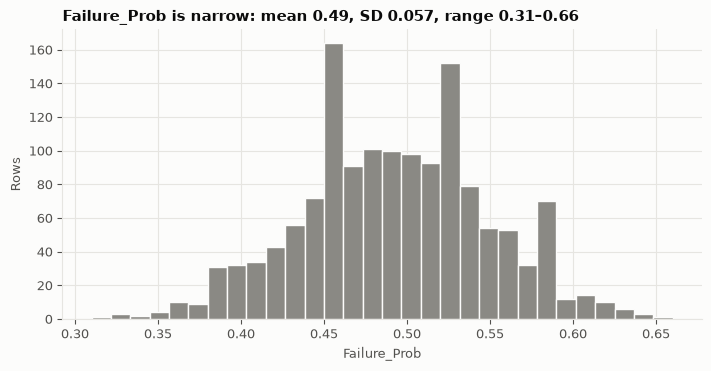

34 distinct values: the target is recorded to the nearest 0.01.


In [5]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.hist(df[TARGET], bins=30, color=NEUTRAL, edgecolor=SURFACE)
ax.set_title(f"Failure_Prob is narrow: mean {df[TARGET].mean():.2f}, SD {df[TARGET].std():.3f}, range {df[TARGET].min():.2f}–{df[TARGET].max():.2f}")
ax.set_xlabel(TARGET)
ax.set_ylabel("Rows")
plt.show()
print(f"{df[TARGET].nunique()} distinct values: the target is recorded to the nearest 0.01.")

<a id="sec-3-2"></a>

### 3.2 Feature distributions

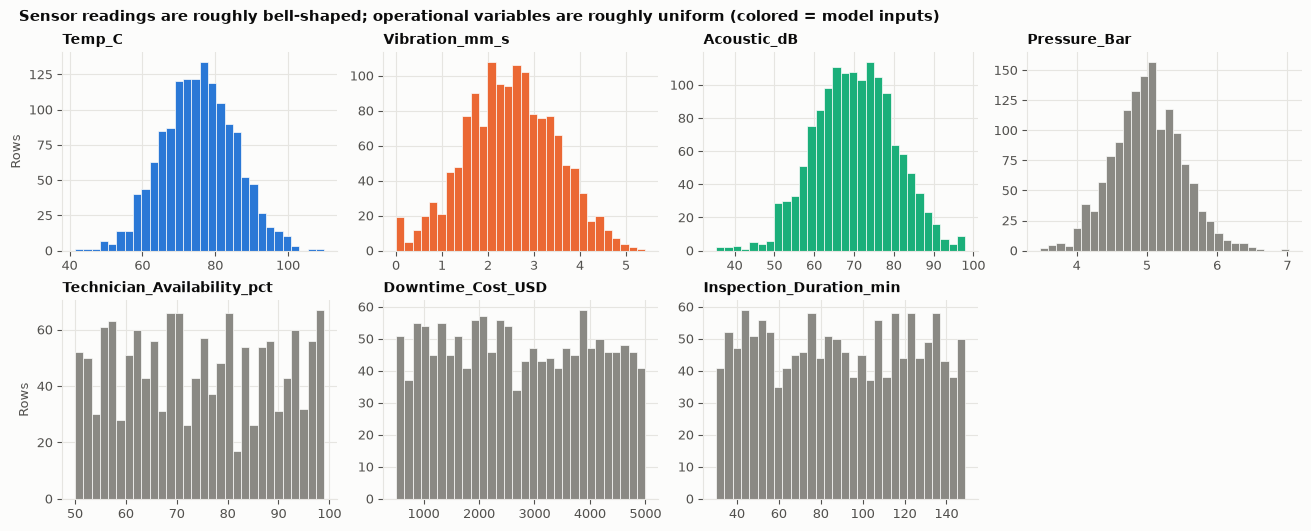

In [6]:
feats = SENSORS + ["Pressure_Bar"] + OPERATIONAL
fig, axes = plt.subplots(2, 4, figsize=(13, 5.2))
for ax, col in zip(axes.ravel(), feats):
    ax.hist(df[col], bins=30, color=SENSOR_COLORS.get(col, NEUTRAL), edgecolor=SURFACE, linewidth=0.5)
    ax.set_title(col, fontsize=10)
axes.ravel()[-1].set_visible(False)
for ax in axes[:, 0]:
    ax.set_ylabel("Rows")
fig.suptitle("Sensor readings are roughly bell-shaped; operational variables are roughly uniform (colored = model inputs)", x=0.01, ha="left", fontsize=11, fontweight="bold")
plt.show()

<a id="sec-3-3"></a>

### 3.3 Outlier screening

In [7]:
rows = []
for col in feats:
    s = df[col]
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    mask = (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)
    rows.append({
        "Feature": col,
        "IQR outliers": int(mask.sum()),
        "% of rows": 100 * mask.mean(),
        "r with target (all rows)": s.corr(df[TARGET]),
        "r with target (outliers removed)": s[~mask].corr(df.loc[~mask, TARGET]),
    })
outlier_tbl = pd.DataFrame(rows).set_index("Feature").round(3)
display(outlier_tbl)

,IQR outliers,% of rows,r with target (all rows),r with target (outliers removed)
Feature,,,,
Temp_C,5,0.350,0.533,0.524
Vibration_mm_s,1,0.070,0.724,0.723
Acoustic_dB,9,0.629,0.393,0.381
Pressure_Bar,17,1.189,-0.019,-0.027
Technician_Availability_pct,0,0.000,-0.279,-0.279
Downtime_Cost_USD,0,0.000,0.009,0.009
Inspection_Duration_min,0,0.000,-0.008,-0.008


Outliers are rare (at most about 1% of rows per feature) and removing them barely moves any correlation, so no rows are dropped.

<a id="sec-3-4"></a>

### 3.4 Correlations

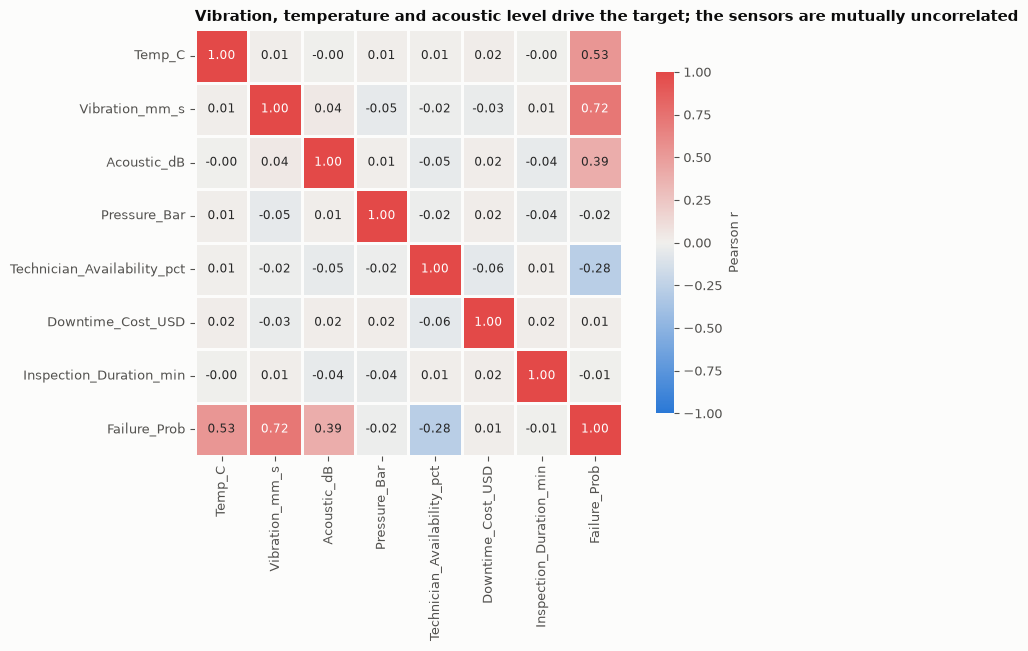

In [8]:
corr = df[feats + [TARGET]].corr()
fig, ax = plt.subplots(figsize=(8.2, 6.4))
sns.heatmap(corr, annot=True, fmt=".2f", cmap=DIVERGING, vmin=-1, vmax=1, square=True,
            linewidths=1, linecolor=SURFACE, cbar_kws={"shrink": 0.8, "label": "Pearson r"},
            annot_kws={"size": 8.5}, ax=ax)
ax.grid(False)
ax.set_title("Vibration, temperature and acoustic level drive the target; the sensors are mutually uncorrelated")
plt.show()

<a id="sec-3-5"></a>

### 3.5 Sensors versus target

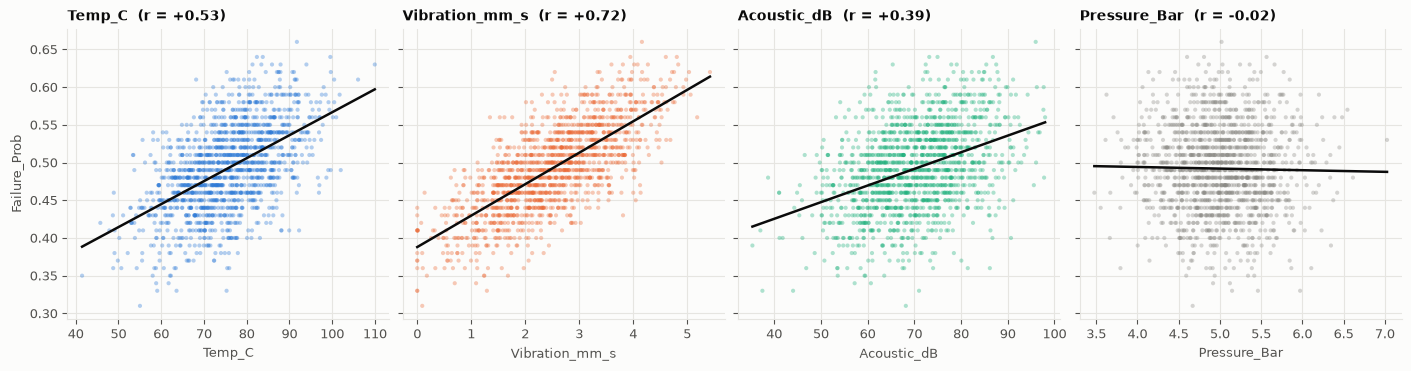

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6), sharey=True)
for ax, col in zip(axes, SENSORS + ["Pressure_Bar"]):
    color = SENSOR_COLORS.get(col, NEUTRAL)
    ax.scatter(df[col], df[TARGET], s=9, alpha=0.35, color=color, edgecolors="none")
    slope, intercept = np.polyfit(df[col], df[TARGET], 1)
    xs = np.linspace(df[col].min(), df[col].max(), 50)
    ax.plot(xs, slope * xs + intercept, color=INK, lw=1.8)
    ax.set_title(f"{col}  (r = {df[col].corr(df[TARGET]):+.2f})", fontsize=10)
    ax.set_xlabel(col)
axes[0].set_ylabel(TARGET)
plt.show()

Each of the three sensors has a clean, roughly straight-line relation with the target. `Pressure_Bar` is flat: no signal.

<a id="sec-3-6"></a>

### 3.6 Machine-level summary

In [10]:
machine_tbl = df.groupby("Machine_ID").agg(
    Rows=("Machine_ID", "size"),
    Mean_Failure_Prob=(TARGET, "mean"),
    SD_Failure_Prob=(TARGET, "std"),
    Mean_Temp_C=("Temp_C", "mean"),
    Mean_Vibration=("Vibration_mm_s", "mean"),
    Mean_Acoustic_dB=("Acoustic_dB", "mean"),
).round(3)
display(machine_tbl)

,Rows,Mean_Failure_Prob,SD_Failure_Prob,Mean_Temp_C,Mean_Vibration,Mean_Acoustic_dB
Machine_ID,,,,,,
M001,167,0.496,0.057,76.880,2.499,69.778
M002,127,0.495,0.055,76.457,2.505,71.040
M003,154,0.496,0.055,75.549,2.583,70.017
M004,127,0.487,0.057,74.593,2.405,70.835
M005,152,0.489,0.057,74.814,2.538,69.368
M006,133,0.490,0.054,75.064,2.459,70.519
M007,142,0.490,0.058,75.838,2.385,69.882
M008,144,0.488,0.059,74.643,2.436,70.478
M009,135,0.494,0.061,74.679,2.564,70.632


The 10 machines look statistically alike (mean failure probability and sensor levels are within a narrow band). This matters later: with so little between-machine variation, grouped cross-validation is a fair but not demanding test of generalization.

<a id="sec-3-7"></a>

### 3.7 Why `Maintenance_Priority` is not a modeling target

In [11]:
rule = np.where(df["Downtime_Cost_USD"] > 4000, 1, np.where(df[TARGET] <= 0.40, 3, 2))
match = (rule == df["Maintenance_Priority"]).mean()
print("Rule: Downtime_Cost_USD > 4000 -> 1; otherwise Failure_Prob <= 0.40 -> 3; otherwise -> 2")
print(f"Rows where the rule equals Maintenance_Priority: {match:.1%}")
display(pd.crosstab(df["Maintenance_Priority"], pd.Series(rule, index=df.index, name="Rule output")))

Rule: Downtime_Cost_USD > 4000 -> 1; otherwise Failure_Prob <= 0.40 -> 3; otherwise -> 2
Rows where the rule equals Maintenance_Priority: 100.0%


Rule output,1,2,3
Maintenance_Priority,,,
1,308,0,0
2,0,1048,0
3,0,0,74


`Maintenance_Priority` is a **deterministic function of `Downtime_Cost_USD` and `Failure_Prob`** (100% of rows). A classifier trained with either column would reach perfect scores by learning the thresholds, and one trained without them would just be a worse version of the regression below followed by a cutoff. Neither says anything about machines, so this notebook models the continuous `Failure_Prob`. If a maintenance priority is needed downstream, apply the rule to a predicted `Failure_Prob` and a known downtime cost.

<a id="sec-4"></a>

## 4. Train/test split and feature selection

In [12]:
# Deterministic transform (no fitted statistics, so no leakage): compound physical stress
df["Severity_Index"] = df["Temp_C"] * df["Vibration_mm_s"]

train, test = train_test_split(df, test_size=TEST_SIZE, random_state=RANDOM_STATE)
X_train, y_train, groups_train = train[SENSORS], train[TARGET], train["Machine_ID"]
X_test, y_test = test[SENSORS], test[TARGET]
print(f"Train: {len(train):,} rows | Test: {len(test):,} rows (random 80/20 split; every machine appears in both)")

Train: 1,144 rows | Test: 286 rows (random 80/20 split; every machine appears in both)


Every candidate feature is screened on the **training split only**. The screening has three parts: statistical (is there signal?), redundancy, and causal plausibility (is there a physical pathway from the variable to a mechanical failure?).

In [13]:
cands = OPERATIONAL + ["Pressure_Bar"]
screen = pd.DataFrame({
    "r with Failure_Prob": train[cands].corrwith(train[TARGET]),
    "max |r| with any sensor": [train[SENSORS].corrwith(train[c]).abs().max() for c in cands],
}).round(3)
display(screen)

resource_risk = train["Downtime_Cost_USD"] / (train["Technician_Availability_pct"] + 1e-5)
print(f"\nResource_Risk (= Downtime_Cost / Technician_Availability) vs Downtime_Cost: r = {resource_risk.corr(train['Downtime_Cost_USD']):.3f} -> redundant, not used")

,r with Failure_Prob,max |r| with any sensor
Technician_Availability_pct,-0.279,0.040
Downtime_Cost_USD,0.004,0.019
Inspection_Duration_min,0.001,0.021
Pressure_Bar,-0.022,0.046



Resource_Risk (= Downtime_Cost / Technician_Availability) vs Downtime_Cost: r = 0.909 -> redundant, not used


In [14]:
def grouped_cv_r2(features, data=train):
    """Mean R2 over machine-grouped folds for a scaled linear regression."""
    pipe = Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())])
    cv = cross_validate(pipe, data[features], data[TARGET], groups=data["Machine_ID"],
                        cv=GroupKFold(n_splits=N_SPLITS), scoring="r2")
    return cv["test_score"].mean()

feature_sets = {
    "3 sensors (modeling set)": SENSORS,
    "+ Pressure_Bar": SENSORS + ["Pressure_Bar"],
    "+ Technician_Availability_pct": SENSORS + ["Technician_Availability_pct"],
    "+ all 3 operational variables": SENSORS + OPERATIONAL,
}
diag = pd.Series({name: grouped_cv_r2(f) for name, f in feature_sets.items()}, name="Grouped-CV R2").round(4)
display(diag.to_frame())

,Grouped-CV R2
3 sensors (modeling set),0.9344
+ Pressure_Bar,0.9344
+ Technician_Availability_pct,0.9969
+ all 3 operational variables,0.9969


**Decisions**
- **`Pressure_Bar` is excluded**: no correlation with the target and no gain in R².
- **`Resource_Risk` is excluded**: redundant with `Downtime_Cost_USD` (r ≈ 0.91).
- **`Technician_Availability_pct`, `Downtime_Cost_USD`, `Inspection_Duration_min` are excluded from the model.** Adding `Technician_Availability_pct` lifts R² from ≈0.93 to ≈0.997, which looks like a gain but is not a sensor-based signal. It is uncorrelated with every sensor (|r| < 0.05) yet strongly related to the target, which is the signature of a term that enters the target directly rather than acting through the physics the sensors measure. A sensor-based model should predict failure from what the sensors see.
- Section 7.4 returns to this: instead of simply excluding the variable, it uses it as a *diagnostic* to explain exactly where the sensor model's remaining error comes from.

Only the three sensors remain: `Temp_C`, `Vibration_mm_s`, `Acoustic_dB`.

<a id="sec-5"></a>

## 5. Model selection

Four candidates are compared with **machine-grouped 5-fold cross-validation** on the training split (`GroupKFold` by `Machine_ID`, so rows from one machine never sit in both the fitting and validation folds). Linear models receive the three raw sensors. Tree ensembles additionally receive `Severity_Index = Temp_C × Vibration_mm_s`, because trees approximate multiplicative interactions poorly without an explicit term. A ridge model (alpha chosen by internal CV) checks whether regularization helps.

In [15]:
TREE_FEATURES = SENSORS + ["Severity_Index"]
candidate_models = {
    "Linear Regression": (Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())]), SENSORS),
    "Ridge (RidgeCV)": (Pipeline([("scaler", StandardScaler()), ("model", RidgeCV(alphas=np.logspace(-3, 3, 25)))]), SENSORS),
    "Random Forest": (RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE), TREE_FEATURES),
    "Gradient Boosting": (GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=RANDOM_STATE), TREE_FEATURES),
}
gkf = GroupKFold(n_splits=N_SPLITS)
scoring = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"}

rows = []
for name, (model, feats_) in candidate_models.items():
    cv = cross_validate(model, train[feats_], y_train, groups=groups_train, cv=gkf, scoring=scoring)
    rows.append({"Model": name, "Features": len(feats_), "CV RMSE": -cv["test_rmse"].mean(),
                 "CV MAE": -cv["test_mae"].mean(), "CV R2": cv["test_r2"].mean()})
comparison = pd.DataFrame(rows).sort_values("CV RMSE").reset_index(drop=True)
display(comparison.round(5))
lr_rmse = comparison.set_index("Model").loc["Linear Regression", "CV RMSE"]
ridge_rmse = comparison.set_index("Model").loc["Ridge (RidgeCV)", "CV RMSE"]
print(f"Linear vs Ridge CV RMSE difference: {abs(lr_rmse - ridge_rmse):.6f} (a tie); best tree model is {comparison[comparison['Model'].str.contains('Forest|Boosting')].iloc[0]['CV RMSE'] / lr_rmse - 1:+.0%} worse than Linear")

,Model,Features,CV RMSE,CV MAE,CV R2
0,Ridge (RidgeCV),3,0.01472,0.01263,0.93443
1,Linear Regression,3,0.01472,0.01263,0.93443
2,Gradient Boosting,4,0.01673,0.01379,0.91529
3,Random Forest,4,0.01754,0.01441,0.90680


Linear vs Ridge CV RMSE difference: 0.000000 (a tie); best tree model is +14% worse than Linear


Linear Regression and Ridge are tied (identical to five decimals: the three sensors are uncorrelated and the data are plentiful, so regularization has nothing to fix), and plain least squares is kept for simplicity and exact interpretability. Random Forest and Gradient Boosting have 14–19% higher RMSE even with the explicit interaction feature. That points to a **linear, additive** relationship, which Section 7 tests directly. Ordinary least squares has no hyperparameters to tune.

<a id="sec-6"></a>

## 6. Final model and evaluation

<a id="sec-6-1"></a>

### 6.1 Held-out test performance

In [16]:
final_model = Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())])
final_model.fit(X_train, y_train)

def regression_metrics(model, X, y):
    p = model.predict(X)
    return {"RMSE": root_mean_squared_error(y, p), "MAE": mean_absolute_error(y, p), "R2": r2_score(y, p)}

perf = pd.DataFrame({"Train": regression_metrics(final_model, X_train, y_train),
                     "Test": regression_metrics(final_model, X_test, y_test)}).T
display(perf.round(4))
print(f"Train/test R2 gap: {perf.loc['Train', 'R2'] - perf.loc['Test', 'R2']:.4f}")

,RMSE,MAE,R2
Train,0.0147,0.0126,0.9352
Test,0.0152,0.0134,0.9199


Train/test R2 gap: 0.0152


<a id="sec-6-2"></a>

### 6.2 Residuals on the test set

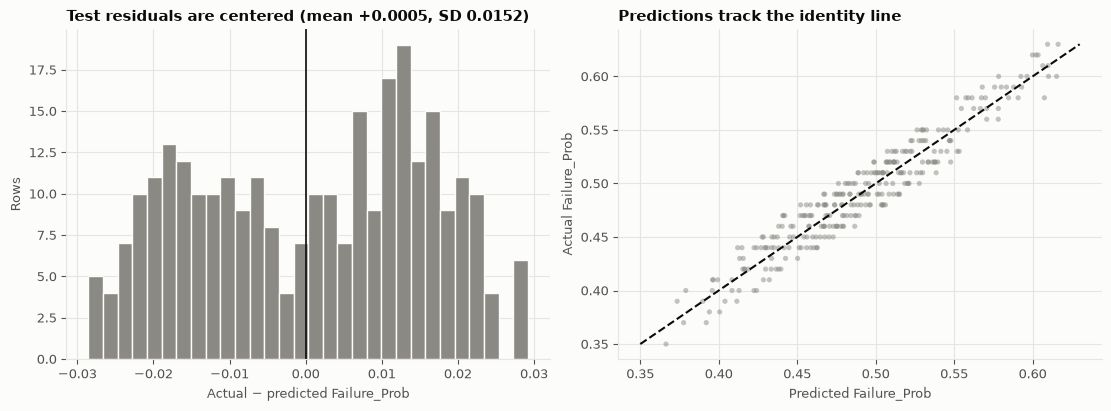

In [17]:
pred_test = final_model.predict(X_test)
resid_test = y_test - pred_test

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(resid_test, bins=30, color=NEUTRAL, edgecolor=SURFACE)
axes[0].axvline(0, color=INK, lw=1.2)
axes[0].set(title=f"Test residuals are centered (mean {resid_test.mean():+.4f}, SD {resid_test.std():.4f})",
            xlabel="Actual − predicted Failure_Prob", ylabel="Rows")

axes[1].scatter(pred_test, y_test, s=14, alpha=0.5, color=NEUTRAL, edgecolors="none")
lims = [min(y_test.min(), pred_test.min()), max(y_test.max(), pred_test.max())]
axes[1].plot(lims, lims, color=INK, lw=1.5, ls="--")
axes[1].set(title="Predictions track the identity line", xlabel="Predicted Failure_Prob", ylabel="Actual Failure_Prob")
plt.show()

<a id="sec-6-3"></a>

### 6.3 Does it transfer to unseen machines? (leave-one-machine-out)

The 80/20 split above is random by row, so test rows come from machines the model has seen. A stricter check: for each machine, train on the other nine and predict the held-out machine. This is an *evaluation only* protocol (the model structure was fixed in Section 5); it also supplies out-of-fold predictions for every row, which Section 7.4 reuses.

,R2,RMSE,Bias
machine,,,
M001,0.9347,0.0145,0.0005
M002,0.9305,0.0145,-0.0023
M003,0.9226,0.0153,0.0008
M004,0.9328,0.0148,-0.0001
M005,0.9352,0.0143,-0.0015
M006,0.9272,0.0146,-0.0005
M007,0.9361,0.0146,0.0019
M008,0.9266,0.0158,0.0008
M009,0.9373,0.0151,0.0008


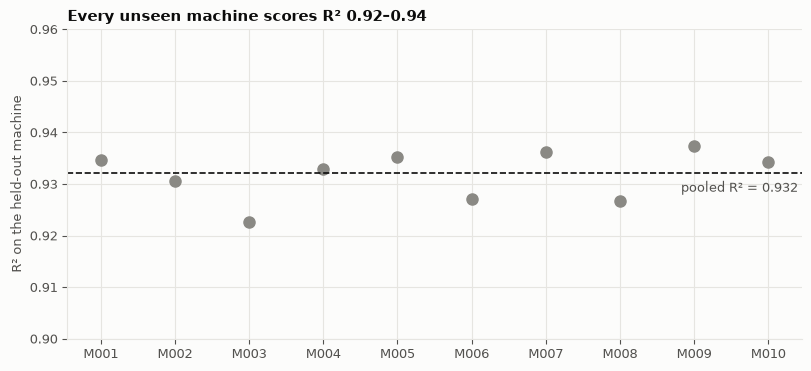

In [18]:
def make_linear():
    return Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())])

def logo_oof(features):
    """Out-of-fold predictions where each machine is predicted by a model that never saw it."""
    return cross_val_predict(make_linear(), df[features], df[TARGET], groups=df["Machine_ID"], cv=LeaveOneGroupOut())

oof_sensors = pd.Series(logo_oof(SENSORS), index=df.index)
oof_df = pd.DataFrame({"machine": df["Machine_ID"], "y": df[TARGET], "p": oof_sensors})
per_machine = oof_df.groupby("machine").apply(
    lambda g: pd.Series({"R2": r2_score(g.y, g.p), "RMSE": root_mean_squared_error(g.y, g.p), "Bias": (g.y - g.p).mean()}),
    include_groups=False,
)
overall_r2 = r2_score(oof_df.y, oof_df.p)
display(per_machine.round(4))

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(per_machine.index, per_machine["R2"], "o", color=NEUTRAL, ms=8)
ax.axhline(overall_r2, color=INK, lw=1.2, ls="--")
ax.text(len(per_machine) - 0.6, overall_r2 - 0.0015, f"pooled R² = {overall_r2:.3f}", va="top", ha="right", color=INK2, fontsize=9)
ax.set(ylim=(0.90, 0.96), ylabel="R² on the held-out machine",
       title=f"Every unseen machine scores R² {per_machine['R2'].min():.2f}–{per_machine['R2'].max():.2f}")
plt.show()

Predicting a machine the model has never seen is about as accurate as predicting a familiar one: R² is 0.92–0.94 for every machine, and the pooled leave-one-machine-out R² (0.932) is close to the test-split R² (0.920, from a 286-row sample). The model captures a property of the sensors, not of individual machines.

<a id="sec-7"></a>

## 7. Explainability (XAI)

Because the final model is a linear model on three uncorrelated sensors, it is **intrinsically interpretable**: its coefficients *are* the explanation. SHAP on a linear model reduces to `coefficient × (x − mean)`, so SHAP alone would add little. The analysis below therefore does four things beyond printing importances:

1. quantifies the model's effects with uncertainty and in physical units (7.1, 7.2);
2. **tests whether the linear story is real** by comparing against a flexible black-box model under SHAP, partial dependence and interaction analysis (7.3);
3. **explains the error**: where the missing ≈7% of variance comes from (7.4);
4. turns the model into decisions: per-row explanations, per-machine risk profiles and what-if changes (7.5, 7.6).

*Throughout, explanations describe how the model relates sensors to the target in this dataset. They are associations, not proof of causal effects on real machines.*

<a id="sec-7-1"></a>

### 7.1 What the model learned: effects with uncertainty

Intercept: 0.0204


,Unit,Coef per unit,95% CI low,95% CI high,p-value,Sensor SD,Effect of +1 SD,Effect CI low,Effect CI high
Temp_C,°C,0.00300,0.00292,0.00309,<0.001,10.13541,0.03043,0.02956,0.03129
Vibration_mm_s,mm/s,0.04065,0.03978,0.04152,<0.001,1.00371,0.04080,0.03993,0.04168
Acoustic_dB,dB,0.00204,0.00196,0.00213,<0.001,10.12698,0.02071,0.01986,0.02155


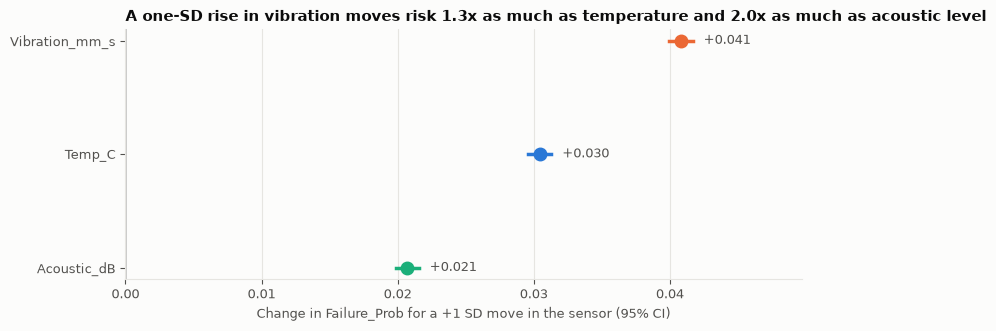

In [19]:
X_sm = sm.add_constant(X_train)
ols = sm.OLS(y_train, X_sm).fit(cov_type="HC3")        # heteroscedasticity-robust standard errors
ci = ols.conf_int()
sd = X_train.std()

# The sklearn pipeline and the raw-unit model are the same function; SHAP and what-if use the raw-unit one.
lin_raw = LinearRegression().fit(X_train, y_train)
assert np.allclose(lin_raw.coef_, ols.params[SENSORS])
assert np.allclose(lin_raw.predict(X_test), final_model.predict(X_test))

coef_tbl = pd.DataFrame({
    "Unit": [SENSOR_UNITS[s] for s in SENSORS],
    "Coef per unit": ols.params[SENSORS],
    "95% CI low": ci.loc[SENSORS, 0],
    "95% CI high": ci.loc[SENSORS, 1],
    "p-value": ols.pvalues[SENSORS],
    "Sensor SD": sd,
})
coef_tbl["Effect of +1 SD"] = coef_tbl["Coef per unit"] * coef_tbl["Sensor SD"]
coef_tbl["Effect CI low"] = coef_tbl["95% CI low"] * coef_tbl["Sensor SD"]
coef_tbl["Effect CI high"] = coef_tbl["95% CI high"] * coef_tbl["Sensor SD"]
print(f"Intercept: {ols.params['const']:.4f}")
display(coef_tbl.round(5).assign(**{"p-value": coef_tbl["p-value"].map(lambda p: "<0.001" if p < 0.001 else f"{p:.3f}")}))

order = coef_tbl["Effect of +1 SD"].abs().sort_values().index
fig, ax = plt.subplots(figsize=(8, 3.2))
for i, s in enumerate(order):
    row = coef_tbl.loc[s]
    ax.plot([row["Effect CI low"], row["Effect CI high"]], [i, i], color=SENSOR_COLORS[s], lw=2.5)
    ax.plot(row["Effect of +1 SD"], i, "o", color=SENSOR_COLORS[s], ms=9)
    ax.text(row["Effect CI high"] + 0.0008, i, f"{row['Effect of +1 SD']:+.3f}", va="center", fontsize=9, color=INK2)
ax.set_yticks(range(len(order)), order)
ax.axvline(0, color=INK, lw=1)
eff = coef_tbl["Effect of +1 SD"]
ax.set(xlim=(0, coef_tbl["Effect CI high"].max() + 0.008), xlabel="Change in Failure_Prob for a +1 SD move in the sensor (95% CI)",
       title=f"A one-SD rise in vibration moves risk {eff['Vibration_mm_s'] / eff['Temp_C']:.1f}x as much as temperature and {eff['Vibration_mm_s'] / eff['Acoustic_dB']:.1f}x as much as acoustic level")
ax.grid(axis="y", visible=False)
plt.show()

**Reading the table.** The coefficients are in probability units per physical unit, e.g. each extra mm/s of vibration adds about 0.04 to `Failure_Prob`, each °C adds 0.003, each dB 0.002. All three are overwhelmingly significant and the confidence intervals are narrow, so the *direction and size* of each effect are stable. Putting sensors on a common footing ("+1 SD") shows vibration is the strongest lever, then temperature, then acoustic level.

<a id="sec-7-2"></a>

### 7.2 Global importance through three lenses

Share of total importance (%) under each lens:


,Drop-one ΔR² (grouped CV),Permutation ΔR² (test),Mean |SHAP| (test)
Temp_C,30.7,29.7,31.9
Vibration_mm_s,55.1,53.0,43.9
Acoustic_dB,14.1,17.3,24.1


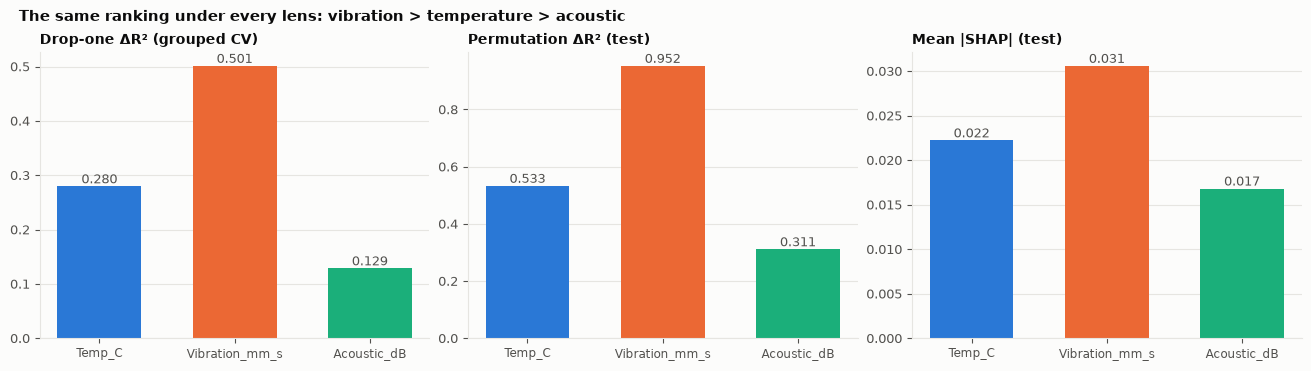

In [20]:
base_r2 = grouped_cv_r2(SENSORS)
drop_one = pd.Series({s: base_r2 - grouped_cv_r2([f for f in SENSORS if f != s]) for s in SENSORS})

perm = permutation_importance(final_model, X_test, y_test, n_repeats=30, random_state=RANDOM_STATE, scoring="r2")
perm_imp = pd.Series(perm.importances_mean, index=SENSORS)

explainer_lin = shap.LinearExplainer(lin_raw, shap.maskers.Independent(X_train, max_samples=len(X_train)))
sv_lin = explainer_lin(X_test)
shap_imp = pd.Series(np.abs(sv_lin.values).mean(axis=0), index=SENSORS)

lens = pd.DataFrame({"Drop-one ΔR² (grouped CV)": drop_one,
                     "Permutation ΔR² (test)": perm_imp,
                     "Mean |SHAP| (test)": shap_imp})
shares = (lens.div(lens.sum()) * 100).round(1)
print("Share of total importance (%) under each lens:")
display(shares)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col in zip(axes, lens.columns):
    vals = lens[col]
    ax.bar(range(3), vals.values, color=[SENSOR_COLORS[s] for s in SENSORS], width=0.62)
    for i, v in enumerate(vals.values):
        ax.text(i, v, f"{v:.3f}", ha="center", va="bottom", fontsize=9, color=INK2)
    ax.set_xticks(range(3), SENSORS, fontsize=8.5)
    ax.set_title(col, fontsize=10)
    ax.grid(axis="x", visible=False)
fig.suptitle("The same ranking under every lens: vibration > temperature > acoustic", x=0.01, ha="left", fontsize=11, fontweight="bold")
plt.show()

All three lenses rank the sensors identically: vibration, then temperature, then acoustic level. The two variance-based lenses (drop-one and permutation) also agree on proportions, roughly 55% / 30% / 15%. Mean |SHAP| is on the probability scale instead of the explained-variance scale, so it spreads credit more evenly (44% / 32% / 24%): explained variance grows with the square of an effect, mean absolute contribution only linearly. The ranking is the robust conclusion; the percentages depend on the lens. For a linear model with independent inputs the lenses are different summaries of the same coefficients, which is why the black-box cross-check in 7.3 is the more informative test.

<a id="sec-7-3"></a>

### 7.3 Cross-check against a black-box model

If the true relationship contained curvature or interactions, a flexible model would find them and its explanations would differ from the linear model's. Gradient Boosting is fit on the **same three raw sensors** (no hand-made interaction feature, so SHAP attributions stay clean), and compared on three fronts: SHAP attributions, partial dependence, and interaction strength.

Gradient Boosting on 3 raw sensors, test R2 = 0.9041 (linear model: 0.9199)
Correlation between linear-model SHAP and Gradient-Boosting SHAP, per sensor:
{'Temp_C': np.float64(0.992), 'Vibration_mm_s': np.float64(0.994), 'Acoustic_dB': np.float64(0.991)}


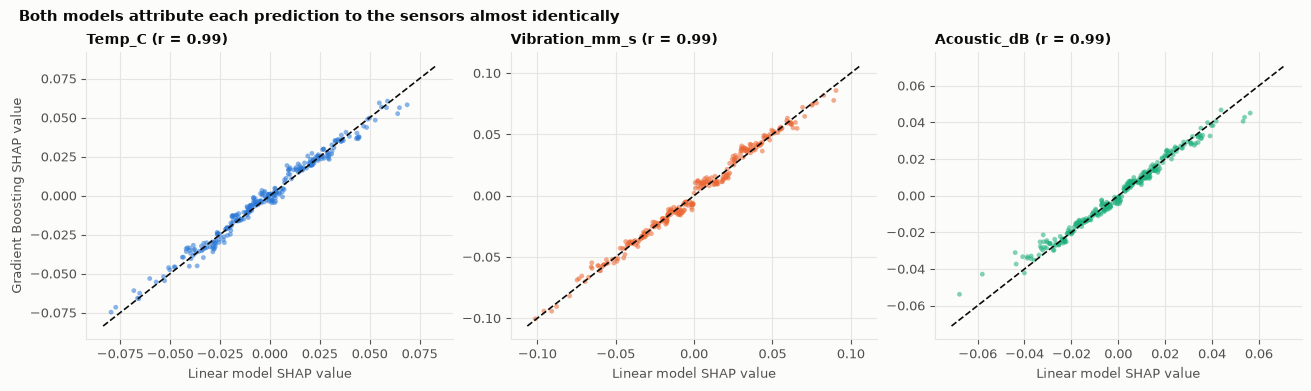

In [21]:
gb = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=RANDOM_STATE).fit(X_train, y_train)
gb_metrics = regression_metrics(gb, X_test, y_test)
print(f"Gradient Boosting on 3 raw sensors, test R2 = {gb_metrics['R2']:.4f} (linear model: {perf.loc['Test', 'R2']:.4f})")

tree_exp = shap.TreeExplainer(gb)
sv_gb = tree_exp(X_test)

agree = {s: np.corrcoef(sv_lin.values[:, j], sv_gb.values[:, j])[0, 1] for j, s in enumerate(SENSORS)}
print("Correlation between linear-model SHAP and Gradient-Boosting SHAP, per sensor:")
print({k: round(v, 3) for k, v in agree.items()})

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for j, (ax, s) in enumerate(zip(axes, SENSORS)):
    ax.scatter(sv_lin.values[:, j], sv_gb.values[:, j], s=12, alpha=0.55, color=SENSOR_COLORS[s], edgecolors="none")
    lim = np.abs(np.r_[sv_lin.values[:, j], sv_gb.values[:, j]]).max() * 1.05
    ax.plot([-lim, lim], [-lim, lim], color=INK, lw=1.2, ls="--")
    ax.set_title(f"{s} (r = {agree[s]:.2f})", fontsize=10)
    ax.set_xlabel("Linear model SHAP value")
axes[0].set_ylabel("Gradient Boosting SHAP value")
fig.suptitle("Both models attribute each prediction to the sensors almost identically", x=0.01, ha="left", fontsize=11, fontweight="bold")
plt.show()

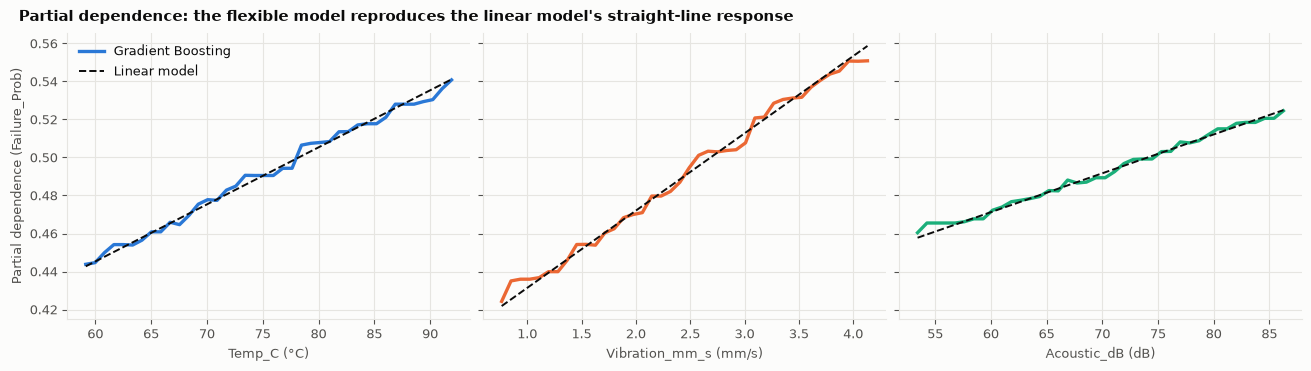

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, s in zip(axes, SENSORS):
    pd_gb = partial_dependence(gb, X_train, [s], grid_resolution=40, kind="average", method="brute")   # "recursion" ignores the GBM init constant
    pd_lin = partial_dependence(lin_raw, X_train, [s], grid_resolution=40, kind="average")
    ax.plot(pd_gb["grid_values"][0], pd_gb["average"][0], color=SENSOR_COLORS[s], lw=2.4)
    ax.plot(pd_lin["grid_values"][0], pd_lin["average"][0], color=INK, lw=1.4, ls="--")
    ax.set_xlabel(f"{s} ({SENSOR_UNITS[s]})")
axes[0].set_ylabel("Partial dependence (Failure_Prob)")
axes[0].legend(handles=[Line2D([0], [0], color=SENSOR_COLORS["Temp_C"], lw=2.4, label="Gradient Boosting"),
                        Line2D([0], [0], color=INK, lw=1.4, ls="--", label="Linear model")], loc="upper left")
fig.suptitle("Partial dependence: the flexible model reproduces the linear model's straight-line response", x=0.01, ha="left", fontsize=11, fontweight="bold")
plt.show()

In [23]:
inter = tree_exp.shap_interaction_values(X_test)           # (rows, 3, 3): diagonal = main effects, off-diagonal = interactions
M = pd.DataFrame(np.abs(inter).mean(axis=0), index=SENSORS, columns=SENSORS)
off_share = (M.values.sum() - np.trace(M.values)) / M.values.sum()
print("Mean |SHAP interaction| matrix (diagonal = main effect, off-diagonal = interaction):")
display(M.round(5))
print(f"Interaction share of total attribution in the black-box model: {off_share:.1%}")

variants = {
    "3 sensors, additive": (make_linear(), SENSORS),
    "+ Temp x Vibration (Severity_Index)": (make_linear(), TREE_FEATURES),
    "+ all squares and pairwise products": (Pipeline([("scaler", StandardScaler()), ("poly", PolynomialFeatures(2, include_bias=False)),
                                                      ("model", LinearRegression())]), SENSORS),
}
cv_rows = {}
for name, (mdl, f) in variants.items():
    cv = cross_validate(mdl, train[f], y_train, groups=groups_train, cv=gkf, scoring="r2")
    cv_rows[name] = cv["test_score"].mean()
inter_tbl = pd.Series(cv_rows, name="Grouped-CV R2").round(4)
display(inter_tbl.to_frame())
print(f"Severity_Index (Temp x Vibration) vs target on the training split: r = {train['Severity_Index'].corr(y_train):.2f}")

Mean |SHAP interaction| matrix (diagonal = main effect, off-diagonal = interaction):


,Temp_C,Vibration_mm_s,Acoustic_dB
Temp_C,0.02160,0.00163,0.00089
Vibration_mm_s,0.00163,0.03152,0.00082
Acoustic_dB,0.00089,0.00082,0.01608


Interaction share of total attribution in the black-box model: 8.8%


,Grouped-CV R2
"3 sensors, additive",0.9344
+ Temp x Vibration (Severity_Index),0.9341
+ all squares and pairwise products,0.9334


Severity_Index (Temp x Vibration) vs target on the training split: r = 0.85


**Verdict: the relationship is additive and linear.** SHAP attributions from the two models agree almost point-for-point (r ≈ 0.99 for every sensor), the black-box response curves follow the linear ones, and supplying `Temp × Vibration` or the full quadratic expansion to the linear model does not improve cross-validated R² (0.934, 0.934, 0.933). Interactions do make up about 9% of the black box's attribution, with Temp × Vibration the largest pair, but a real interaction would improve the linear model once given explicitly, so this is better read as the tree ensemble spending capacity on noise. That fits its lower test R² (0.904 vs 0.920).

This also settles the earlier claim that failure probability is "dominated by a temperature × vibration interaction". `Severity_Index` correlates well with the target (r ≈ 0.85) only because it bundles two individually strong sensors; as an interaction, it adds no information beyond them.

<a id="sec-7-4"></a>

### 7.4 What the model cannot explain: residual analysis

The sensor model leaves ≈7% of the target's variance unexplained. Out-of-fold residuals (leave-one-machine-out, Section 6.3) are used so the check is not flattered by in-sample fitting. First: do the residuals still depend on the sensors (missed curvature), or on something else?

Correlation of out-of-fold residuals with each variable:


,r with residual
Technician_Availability_pct,-0.976
Downtime_Cost_USD,0.059
Pressure_Bar,0.024
Inspection_Duration_min,-0.004
Temp_C,-0.001
Vibration_mm_s,-0.001
Acoustic_dB,-0.000


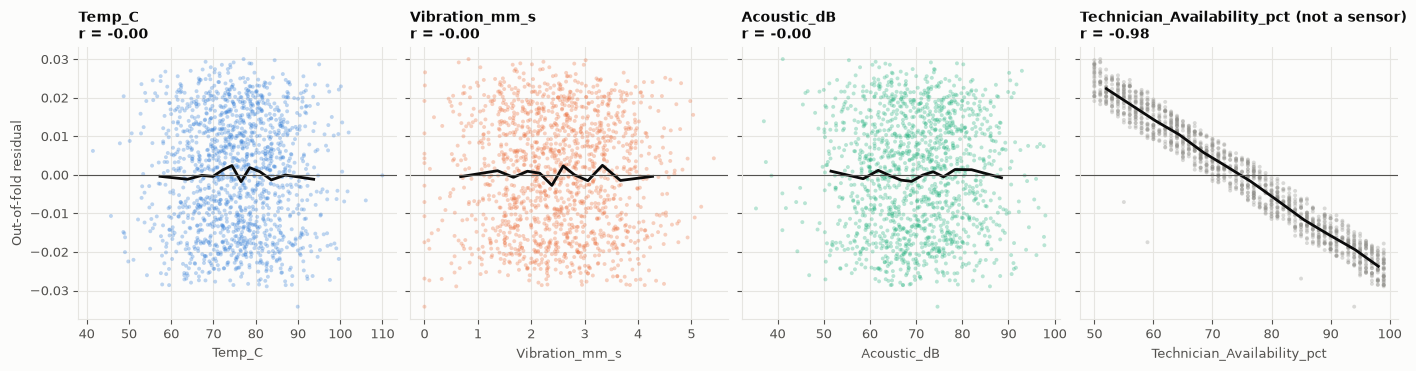

In [24]:
resid = df[TARGET] - oof_sensors
check_cols = SENSORS + ["Pressure_Bar"] + OPERATIONAL
resid_corr = df[check_cols].corrwith(resid).round(3).sort_values(key=np.abs, ascending=False)
print("Correlation of out-of-fold residuals with each variable:")
display(resid_corr.to_frame("r with residual"))

panels = SENSORS + ["Technician_Availability_pct"]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6), sharey=True)
for ax, col in zip(axes, panels):
    color = SENSOR_COLORS.get(col, NEUTRAL)
    ax.scatter(df[col], resid, s=8, alpha=0.3, color=color, edgecolors="none")
    bins = pd.qcut(df[col], 12, duplicates="drop")
    g = pd.DataFrame({"x": df[col], "r": resid}).groupby(bins, observed=True).mean()
    ax.plot(g["x"], g["r"], color=INK, lw=2)
    ax.axhline(0, color=INK2, lw=0.8)
    title = col if col in SENSORS else "Technician_Availability_pct (not a sensor)"
    ax.set_title(f"{title}\nr = {df[col].corr(resid):+.2f}", fontsize=10)
    ax.set_xlabel(col)
axes[0].set_ylabel("Out-of-fold residual")
plt.show()

The residuals are flat against all three sensors (no missed curvature, consistent with 7.3) but fall almost perfectly along a straight line in `Technician_Availability_pct`. The sensor model's error is therefore not random: **nearly all of it is one additive, non-sensor term.**

,R2 (leave-one-machine-out),RMSE
3 sensors,0.9321,0.0148
+ Technician_Availability_pct,0.9969,0.0032
+ all other variables,0.9969,0.0032


RMSE floor from recording Failure_Prob to the nearest 0.01: 0.0029


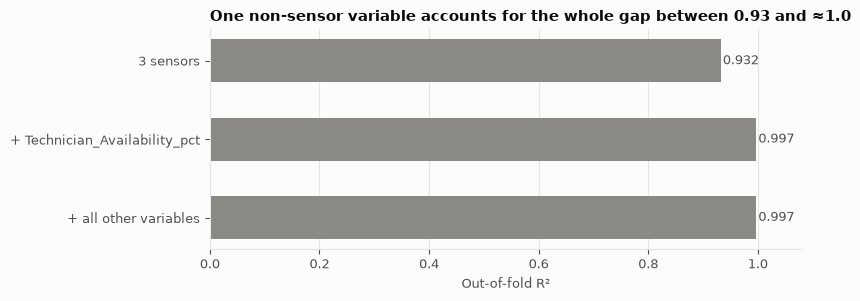

In [25]:
sets = {
    "3 sensors": SENSORS,
    "+ Technician_Availability_pct": SENSORS + ["Technician_Availability_pct"],
    "+ all other variables": SENSORS + ["Technician_Availability_pct", "Downtime_Cost_USD", "Inspection_Duration_min", "Pressure_Bar"],
}
acct = {}
for name, f in sets.items():
    p = logo_oof(f)
    acct[name] = {"R2 (leave-one-machine-out)": r2_score(df[TARGET], p), "RMSE": root_mean_squared_error(df[TARGET], p)}
acct = pd.DataFrame(acct).T
display(acct.round(4))
rounding_rmse = 0.01 / np.sqrt(12)
print(f"RMSE floor from recording Failure_Prob to the nearest 0.01: {rounding_rmse:.4f}")

fig, ax = plt.subplots(figsize=(8, 2.9))
vals = acct["R2 (leave-one-machine-out)"]
ypos = np.arange(len(vals))[::-1]
ax.barh(ypos, vals.values, color=NEUTRAL, height=0.55)
for y_, v in zip(ypos, vals.values):
    ax.text(v + 0.004, y_, f"{v:.3f}", va="center", fontsize=9.5, color=INK2)
ax.set_yticks(ypos, vals.index)
ax.set(xlim=(0, 1.08), xlabel="Out-of-fold R²", title="One non-sensor variable accounts for the whole gap between 0.93 and ≈1.0")
ax.grid(axis="y", visible=False)
plt.show()

Adding `Technician_Availability_pct` takes out-of-fold R² from ≈0.93 to ≈0.997, and the RMSE falls to 0.0032, within 0.0003 of the 0.0029 floor imposed by recording the target to the nearest 0.01. Nothing else (pressure, cost, inspection time) adds anything. In other words, **the sensors explain essentially everything the sensors *can* explain; the remainder is a single, sensor-independent effect.**

Two consequences:
- *Deliberately leaving it out is not costly to the sensor effects.* Because it is uncorrelated with the sensors, omitting it should not bias their coefficients. The next cell verifies this (they move by less than 3%).
- *Whether to model it is a scope decision, not a statistical one.* If staffing level really influences failure (for example through maintenance quality), a model for operational planning could include it. A model meant to read machine health from sensors should not, and this notebook keeps it out of the model.

In [26]:
with_tech = LinearRegression().fit(train[SENSORS + ["Technician_Availability_pct"]], y_train)
stab = pd.DataFrame({
    "Sensors only": lin_raw.coef_,
    "Sensors + Technician": with_tech.coef_[:3],
}, index=SENSORS)
stab["Change (%)"] = 100 * (stab["Sensors + Technician"] / stab["Sensors only"] - 1)
display(stab.round(5))
print(f"Technician coefficient: {with_tech.coef_[3]:.5f} per percentage point of availability")

,Sensors only,Sensors + Technician,Change (%)
Temp_C,0.00300,0.00301,0.28911
Vibration_mm_s,0.04065,0.04027,-0.94810
Acoustic_dB,0.00204,0.00199,-2.64982


Technician coefficient: -0.00100 per percentage point of availability


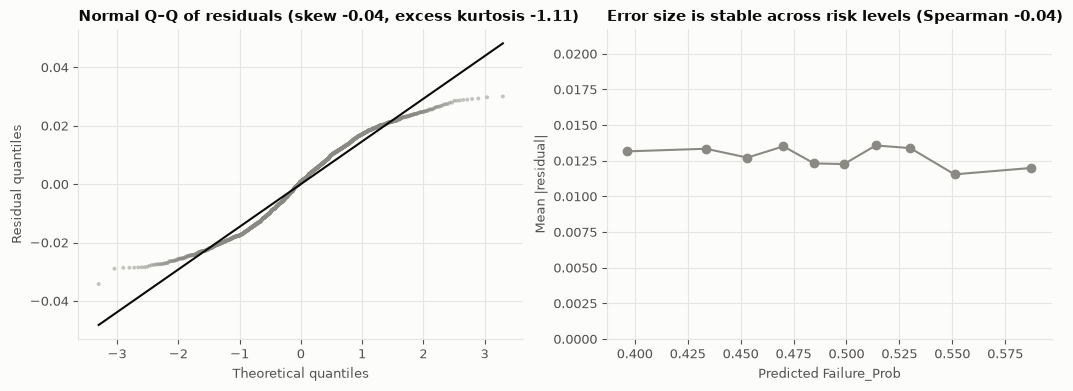

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8))
(osm, osr), (slope, intercept, r_qq) = stats.probplot(resid, dist="norm")
axes[0].scatter(osm, osr, s=8, alpha=0.5, color=NEUTRAL, edgecolors="none")
axes[0].plot(osm, slope * osm + intercept, color=INK, lw=1.5)
axes[0].set(title=f"Normal Q–Q of residuals (skew {stats.skew(resid):+.2f}, excess kurtosis {stats.kurtosis(resid):+.2f})",
            xlabel="Theoretical quantiles", ylabel="Residual quantiles")

bins = pd.qcut(oof_sensors, 10)
g = pd.DataFrame({"pred": oof_sensors, "abs_resid": resid.abs()}).groupby(bins, observed=True).mean()
axes[1].plot(g["pred"], g["abs_resid"], "o-", color=NEUTRAL, lw=1.5, ms=6)
axes[1].set(ylim=(0, g["abs_resid"].max() * 1.6), xlabel="Predicted Failure_Prob", ylabel="Mean |residual|",
            title=f"Error size is stable across risk levels (Spearman {stats.spearmanr(oof_sensors, resid.abs())[0]:+.2f})")
plt.show()

The leftover error has constant spread across the risk range, so a single error band applies equally at low and high predicted risk. It is **not Gaussian**, though: it is flat-topped and bounded (excess kurtosis ≈ −1.1, close to the −1.2 of a uniform distribution; no residual exceeds about ±0.035). That is what one would expect if the error is mainly one uniformly distributed variable (technician availability spans 50–99%) plus rounding. Normal-theory prediction intervals would therefore be slightly too wide at the tails; the empirical residual range is the more honest band.

<a id="sec-7-5"></a>

### 7.5 Local explanations and per-machine risk profiles

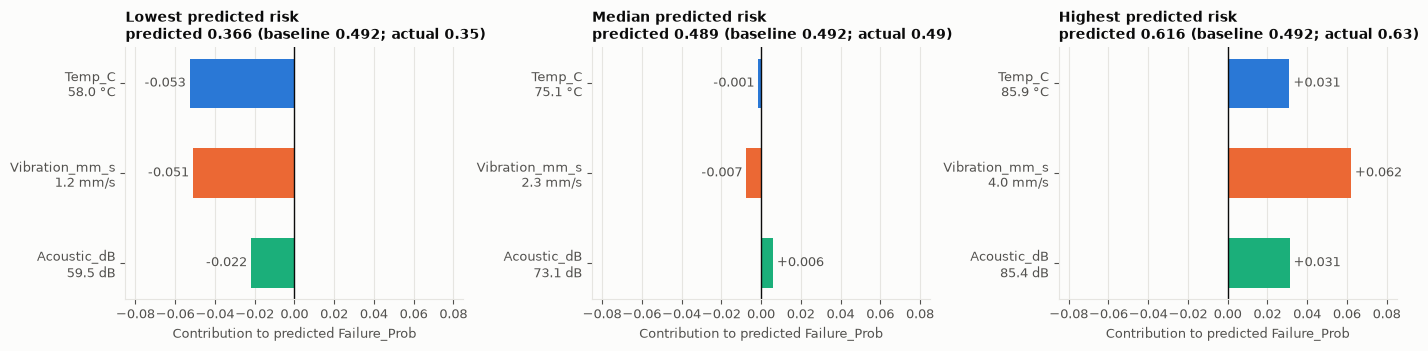

In [28]:
pred_lin = pd.Series(lin_raw.predict(X_test), index=X_test.index)
ranked = pred_lin.sort_values()
picks = {"Lowest predicted risk": ranked.index[0],
         "Median predicted risk": ranked.index[len(ranked) // 2],
         "Highest predicted risk": ranked.index[-1]}
base_value = float(sv_lin.base_values[0])

fig, axes = plt.subplots(1, 3, figsize=(14, 3.4), sharex=True)
for ax, (label, idx) in zip(axes, picks.items()):
    pos = X_test.index.get_loc(idx)
    contrib = pd.Series(sv_lin.values[pos], index=SENSORS)
    ypos = np.arange(3)[::-1]
    ax.barh(ypos, contrib.values, color=[SENSOR_COLORS[s] for s in SENSORS], height=0.55)
    for y_, s in zip(ypos, SENSORS):
        c = contrib[s]
        ax.text(c + (0.002 if c >= 0 else -0.002), y_, f"{c:+.3f}", va="center", ha="left" if c >= 0 else "right", fontsize=9, color=INK2)
    ax.set_yticks(ypos, [f"{s}\n{X_test.loc[idx, s]:.1f} {SENSOR_UNITS[s]}" for s in SENSORS])
    ax.axvline(0, color=INK, lw=1)
    ax.set_title(f"{label}\npredicted {pred_lin[idx]:.3f} (baseline {base_value:.3f}; actual {y_test[idx]:.2f})", fontsize=10)
    ax.set_xlim(-0.085, 0.085)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("Contribution to predicted Failure_Prob")
plt.show()
assert np.allclose(sv_lin.base_values + sv_lin.values.sum(axis=1), pred_lin.values)   # SHAP is exactly additive

Each bar shows how far a sensor reading pushes this machine-reading above or below the fleet baseline. The three profiles are exactly additive (baseline + contributions = prediction), so a maintenance engineer can read off *which* sensor is responsible for an elevated risk and by how much.

,Temp_C,Vibration_mm_s,Acoustic_dB,Predicted risk,Actual risk
Machine_ID,,,,,
M002,0.0027,0.0005,0.0018,0.4970,0.4950
M001,0.0040,0.0003,-0.0008,0.4955,0.4960
M003,-0.0000,0.0037,-0.0003,0.4954,0.4962
M010,0.0007,0.0026,-0.0014,0.4940,0.4936
M009,-0.0027,0.0029,0.0010,0.4933,0.4941
M005,-0.0023,0.0019,-0.0016,0.4900,0.4888
M006,-0.0015,-0.0013,0.0007,0.4899,0.4895
M007,0.0008,-0.0043,-0.0006,0.4879,0.4898
M008,-0.0028,-0.0023,0.0006,0.4876,0.4885


Typical standard error of a machine's mean contribution (pure sampling noise): {'Temp_C': 0.0025, 'Vibration_mm_s': 0.0034, 'Acoustic_dB': 0.0017}


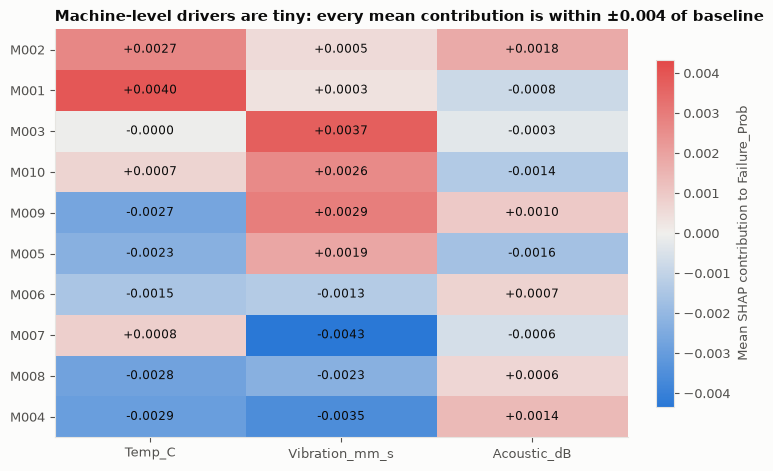

In [29]:
sv_all = explainer_lin(df[SENSORS])
contrib_all = pd.DataFrame(sv_all.values, columns=SENSORS, index=df.index)
contrib_all["Machine_ID"] = df["Machine_ID"]
mp = contrib_all.groupby("Machine_ID")[SENSORS].mean()
mp["Predicted risk"] = pd.Series(lin_raw.predict(df[SENSORS]), index=df.index).groupby(df["Machine_ID"]).mean()
mp["Actual risk"] = df.groupby("Machine_ID")[TARGET].mean()
mp = mp.sort_values("Predicted risk", ascending=False)
display(mp.round(4))
se = contrib_all.groupby("Machine_ID")[SENSORS].std().div(np.sqrt(df.groupby("Machine_ID").size()), axis=0).mean()
print("Typical standard error of a machine's mean contribution (pure sampling noise):", se.round(4).to_dict())

vmax = np.abs(mp[SENSORS].values).max()
fig, ax = plt.subplots(figsize=(7.5, 4.6))
im = ax.imshow(mp[SENSORS].values, cmap=DIVERGING, vmin=-vmax, vmax=vmax, aspect="auto")
ax.set_xticks(range(3), SENSORS)
ax.set_yticks(range(len(mp)), mp.index)
for i in range(len(mp)):
    for j in range(3):
        ax.text(j, i, f"{mp.iloc[i, j]:+.4f}", ha="center", va="center", fontsize=8.5, color=INK)
ax.grid(False)
fig.colorbar(im, ax=ax, label="Mean SHAP contribution to Failure_Prob", shrink=0.85)
ax.set_title(f"Machine-level drivers are tiny: every mean contribution is within ±{vmax:.3f} of baseline")
plt.show()

Machines are ranked by mean predicted risk, with each sensor's mean contribution. Everything here is small: no contribution exceeds about ±0.005 and the typical sampling error of a machine's mean is of the same order (printed above), so the ranking and the colors largely reflect chance. **No machine has a distinctive sensor signature**, which supports a fleet-wide policy keyed to the strongest sensor (vibration) rather than machine-specific rules. On real data with heterogeneous machines the same view would be the place to look for machines that deviate.

<a id="sec-7-6"></a>

### 7.6 What-if analysis

Because the model is linear, "what change in a sensor would bring risk down?" has a closed-form answer. First, the size of each lever, then concrete suggestions for the highest-risk test readings. Suggestions that would push a sensor below anything observed in the training data are flagged as infeasible rather than extrapolated.

In [30]:
coef = pd.Series(lin_raw.coef_, index=SENSORS)
DELTA = 0.03
lever = pd.DataFrame({
    "Unit": [SENSOR_UNITS[s] for s in SENSORS],
    f"Change needed to lower risk by {DELTA}": -DELTA / coef,
    "... as multiples of sensor SD": (-DELTA / coef) / X_train.std(),
})
display(lever.round(3))

,Unit,Change needed to lower risk by 0.03,... as multiples of sensor SD
Temp_C,°C,-9.993,-0.986
Vibration_mm_s,mm/s,-0.738,-0.735
Acoustic_dB,dB,-14.671,-1.449


In [31]:
sensor_min = X_train.min()
fleet_target = float(lin_raw.predict(X_train).mean())      # bring a reading down to the fleet-average predicted risk

def required_change(row, target):
    """Single-sensor change that moves the predicted risk to `target`; flags values below the training minimum."""
    gap = float(lin_raw.predict(row[SENSORS].to_frame().T)[0]) - target
    out = {}
    for s in SENSORS:
        delta = -gap / coef[s]
        feasible = (row[s] + delta) >= sensor_min[s]
        out[f"{s} ({SENSOR_UNITS[s]})"] = f"{delta:+.2f}" + ("" if feasible else " (infeasible)")
    return out

top = pred_lin.sort_values(ascending=False).head(5).index
rows = []
for idx in top:
    r = {"Row": idx, "Machine": df.loc[idx, "Machine_ID"], "Predicted risk": round(pred_lin[idx], 3)}
    r.update(required_change(test.loc[idx], fleet_target))
    k = (pred_lin[idx] - fleet_target) / (coef * X_train.std()).sum()      # same cut, in SDs, applied to all three sensors at once
    r["Uniform cut in all 3 sensors (SD)"] = round(k, 2)
    rows.append(r)
print(f"Target: fleet-average predicted risk = {fleet_target:.3f}. Each column is a change to ONE sensor, others held fixed.")
display(pd.DataFrame(rows).set_index("Row"))

Target: fleet-average predicted risk = 0.492. Each column is a change to ONE sensor, others held fixed.


,Machine,Predicted risk,Temp_C (°C),Vibration_mm_s (mm/s),Acoustic_dB (dB),Uniform cut in all 3 sensors (SD)
Row,,,,,,
1385,M003,0.616,-41.39,-3.06,-60.76 (infeasible),1.35
867,M007,0.615,-41.06,-3.03,-60.28,1.34
1110,M004,0.610,-39.34,-2.91,-57.76 (infeasible),1.28
566,M007,0.610,-39.24 (infeasible),-2.90,-57.61 (infeasible),1.28
570,M001,0.610,-39.15,-2.89,-57.47 (infeasible),1.28


Reading the table: the five riskiest test readings sit about 0.12 above the fleet average (roughly 2 SD of the target), a large gap. Closing it through a single sensor takes about a 3 mm/s cut in vibration (≈3 SD), a 40 °C cut in temperature (≈4 SD, possible only when the reading is hot enough to stay inside the observed range) or a 60 dB cut in acoustic level (≈6 SD, mostly below anything observed, hence flagged infeasible). Vibration is the most efficient single lever, but for the worst readings the realistic route is a combined improvement: lowering **all three** sensors by about 1.3 SD would return them to the fleet average.

*Caveat:* these are **predictive what-ifs on an observational (and, as noted below, probably synthetic) dataset**. They say how the model's output moves, not that physically reducing the sensor reading would reduce real failure risk. A sensor reading is a symptom; the intervention is on the machine.

<a id="sec-7-7"></a>

### 7.7 Influence and data quality

In [32]:
ols_plain = sm.OLS(y_train, X_sm).fit()
cooks = pd.Series(ols_plain.get_influence().cooks_distance[0], index=train.index)
thresh = 4 / len(train)
print(f"Cook's distance > 4/n ({thresh:.4f}): {(cooks > thresh).sum()} of {len(train)} training rows; max = {cooks.max():.4f}")
display(train.loc[cooks.sort_values(ascending=False).head(5).index, ["Machine_ID"] + SENSORS + [TARGET]].assign(Cooks_D=cooks.round(4)).round(3))

clipped_in_train = train.index.intersection(neg_vib_idx)
keep = ~train.index.isin(neg_vib_idx)
no_clip = LinearRegression().fit(train.loc[keep, SENSORS], y_train[keep])
infl = pd.DataFrame({"All training rows": lin_raw.coef_, "Without clipped-vibration rows": no_clip.coef_}, index=SENSORS)
infl["Change (%)"] = 100 * (infl["Without clipped-vibration rows"] / infl["All training rows"] - 1)
print(f"\n{len(clipped_in_train)} of the 11 clipped-vibration rows are in the training split. Coefficients with and without them:")
display(infl.round(5))

Cook's distance > 4/n (0.0035): 45 of 1144 training rows; max = 0.0110


,Machine_ID,Temp_C,Vibration_mm_s,Acoustic_dB,Failure_Prob,Cooks_D
975,M010,77.136,0.826,41.133,0.40,0.011
1324,M008,89.947,0.000,74.632,0.41,0.011
1233,M001,63.133,4.046,50.369,0.45,0.007
865,M001,82.618,0.596,85.990,0.44,0.007
390,M004,58.822,1.051,90.683,0.40,0.006



10 of the 11 clipped-vibration rows are in the training split. Coefficients with and without them:


,All training rows,Without clipped-vibration rows,Change (%)
Temp_C,0.00300,0.00301,0.17450
Vibration_mm_s,0.04065,0.04052,-0.32330
Acoustic_dB,0.00204,0.00205,0.08356


No single row dominates the fit (the largest Cook's distance is far below 1, the usual alarm level), and removing the clipped-vibration rows changes the coefficients negligibly. The explanations in this section are not an artifact of a few bad readings.

<a id="sec-8"></a>

## 8. Conclusions and limitations

### What the analysis shows

- **Performance.** A linear regression on three sensors (`Temp_C`, `Vibration_mm_s`, `Acoustic_dB`) reaches **test R² = 0.920** (RMSE 0.0152, MAE 0.0134 on a target with SD 0.057). Machine-grouped CV gives 0.934, and predicting each machine from the other nine gives R² 0.92–0.94 for every machine (pooled 0.932), so the model does not depend on having seen a particular machine.
- **What drives failure probability.** Vibration is the strongest lever (+0.041 per mm/s), then temperature (+0.0030 per °C) and acoustic level (+0.0020 per dB); per standard deviation these are +0.041, +0.030 and +0.021. The ranking is identical under drop-one, permutation and SHAP importance, and the roughly 55% / 30% / 15% split holds under both variance-based lenses.
- **The relationship is additive and linear.** A Gradient Boosting model on the same sensors produces SHAP attributions that correlate at r ≈ 0.99 with the linear model's, has straight partial-dependence curves and a *lower* test R² (0.904). Explicit interaction or quadratic terms do not improve the linear model. The earlier idea that failure probability is "dominated by a temperature × vibration interaction" is not supported: `Severity_Index` correlates with the target (r ≈ 0.85) only because it bundles two strong sensors.
- **Where the missing 7% goes.** Out-of-fold residuals are uncorrelated with every sensor but correlate at r = −0.98 with `Technician_Availability_pct`. Adding that one variable raises out-of-fold R² from 0.932 to 0.997 and brings the RMSE to within 0.0003 of the floor set by rounding the target to 0.01. The sensors explain everything the sensors can explain; the rest is one independent, non-sensor effect. Leaving it out does not distort the sensor effects (coefficients move by less than 3%).
- **Residuals** have constant spread across risk levels but are flat-topped and bounded (excess kurtosis ≈ −1.1, none beyond about ±0.035), so empirical error bands are more accurate than normal-theory ones.
- **Machines are interchangeable.** Per-machine sensor contributions are within sampling noise of zero, so there is no evidence for machine-specific rules; a fleet-wide policy keyed to vibration is the natural choice.
- **Robustness.** No single row dominates the fit (max Cook's distance 0.011), and removing the clipped negative-vibration rows changes coefficients by under 0.4%.
- **Why there is no classifier.** `Maintenance_Priority` is reproduced exactly by `Downtime_Cost_USD > 4000 → 1`, else `Failure_Prob ≤ 0.40 → 3`, else `2`. A model of it only rediscovers those thresholds. A priority can be produced by applying the rule to a predicted `Failure_Prob` and a known downtime cost.

### Limitations

- **The data look synthetic.** The target is an additive linear function of three sensors plus one independent uniform variable, down to rounding precision, and the priority label is a pure threshold rule. The explanations therefore tell us how the model relates inputs to outputs *in this dataset*; real machines will likely show nonlinear wear, interactions and drift that this data cannot reveal. Treat the numbers as a worked example of the method, not as engineering constants.
- **Associational, not causal.** SHAP values and what-if changes describe the model, not interventions on a machine. A sensor reading is a symptom; lowering vibration on paper is not the same as repairing the bearing that causes it.
- **Scope decision on `Technician_Availability_pct`.** It is excluded because this is a sensor-based model. If staffing really influences failure (for example through maintenance quality), a planning model could include it; the diagnostics above show what that would add (≈ +0.065 R²).
- **Small, static data.** Ten machines and no timestamps: the notebook cannot assess drift, time-to-failure, or generalization to machines with different operating regimes. The held-out test split is random by row (every machine appears in both parts); Section 6.3 adds the stricter leave-one-machine-out view.
- **Independent sensors make attribution easy.** Because the three sensors are uncorrelated (|r| ≤ 0.05), importance is unambiguous. With correlated sensors, the lenses in 7.2 would disagree and would need more careful treatment.